# DDS-8555 Assignment 5: Build and Evaluate Classification Models
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. When the upload button appears, choose the Kaggle zip (only the first time). The five Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Rubric item | Where |
|---|---|
| Completes Conceptual Question (ISLP Ch. 4, Q1) | Part 1 |
| Completes Applied Question (ISLP Ch. 4, Q13, Weekly data) | Part 2 |
| Submits LDA/QDA models to Kaggle | Part 3, Model 2 (both LDA and QDA submitted) |
| Submits NB/SVM models to Kaggle | Part 3, Models 3 and 4 |
| Multinomial logistic regression | Part 3, Model 1 |
| Applies regularized regression | Part 3, Model 1 (ridge- and lasso-penalized multinomial logistic regression, penalty chosen by CV); also shrinkage LDA and regularized QDA |
| Investigates assumptions | Part 3, assumption checks |
| Provides evidence of submissions | Screenshot in the paper's appendix |
| Posts code to GitHub | This notebook (repo DDS8555) |

In [1]:
# ==============================================================================
# DDS-8555 Predictive Analysis | Assignment 5 (Part 1 of 1): Build and Evaluate Classification Models
# National University | Instructor: Dr. Alexander V. Watt | Author: Nathan Weber
# Notebook: DDS8555_ASGN5Part1of1_Classification_NWeber.ipynb
# Paper:    WeberN_DDS8555-910002634_ASGN5Part1of1.docx  (the written report; code is not reproduced there)
# Version:  v1.0, 2026-10-20 (see the change log at the end of this cell)
# ------------------------------------------------------------------------------
# RUN:      Google Colab -> Runtime -> Run all (also runs locally with Python 3.10+).
#           Needs: numpy, pandas, matplotlib, scikit-learn, statsmodels, scipy, ISLP.
# INPUTS:   Kaggle 'Multi-Class Prediction of Obesity Risk' (playground-series-s4e2):
#           train.csv, test.csv, sample_submission.csv (or the zip) in
#           Google Drive/MyDrive/DDS8555/obesity. Textbook data come from the ISLP package.
#           https://www.kaggle.com/competitions/playground-series-s4e2
#           (synthetic data generated from the UCI obesity-levels data;
#           original: Palechor & de la Hoz Manotas, 2019, https://doi.org/10.1016/j.dib.2019.104344)
# OUTPUTS:  Drive/MyDrive/DDS8555/output: A5_model1_logistic.csv, A5_model2a_lda.csv, A5_model2b_qda.csv, A5_model3_naive_bayes.csv, A5_model4_svm.csv, A5_fig_weekly.png, A5_fig_regularization.png, A5_fig_confusion.png, A5_results.json
# ------------------------------------------------------------------------------
# QUESTION: Four classifiers for the seven obesity classes: penalized multinomial logistic regression, LDA and QDA, Gaussian naive Bayes, and a support vector machine (RBF kernel), compared by 5-fold CV accuracy and Kaggle accuracy. Also ISLP Ch. 4 conceptual Q1 and applied Q13 (Weekly).
# TARGET:   NObeyesdad (7 weight classes). Kaggle metric = accuracy (share of rows classed correctly).
# CLEANING (same in A5 and A6): no rows dropped; categorical levels one-hot encoded (levels unseen
#           in training, e.g. CALC = 'Always' in test, are ignored); numeric columns standardized
#           where a model needs it; one added feature, BMI = Weight / Height^2.
# VALIDATION: 5-fold StratifiedKFold(shuffle=True, random_state=42) on the training set only.
#           The Kaggle test set has no labels; it is scored only by Kaggle.
# SEEDS:    random_state=42 for CV folds and models; the SVM tuning subsample uses random_state=42.
# DEPENDS ON: None upstream. This notebook sets the load cell and BMI feature reused unchanged in A6; the A5 logistic model is the A6 baseline.
# CHECKS:   input SHA-256 fingerprints, row counts, column names, and package versions
#           are printed below and at the end, so a re-run can be compared line by line.
# ------------------------------------------------------------------------------
# CHANGE LOG:
#   v1.0  2026-10-20  First version.
# ==============================================================================

In [2]:
## ---- 0. Setup and imports ------------------------------------------------------
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, time, warnings
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/DDS8555"
    !pip -q install --no-deps ISLP
else:
    BASE = os.environ.get("DDS8555_BASE", ".")
DATA_DIR = os.path.join(BASE, "obesity")
OUT_DIR = os.path.join(BASE, "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from ISLP import load_data
pd.set_option("display.width", 120); pd.set_option("display.max_columns", 25)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end
T0 = time.time()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1. Conceptual Question 1 (ISLP Chapter 4)
*Question (paraphrased; ISLP p. 193):* using a little algebra, show that the logistic function (4.2) and the logit, or log-odds, representation (4.3) of the logistic regression model are equivalent.

Start from (4.2): p(X) = e^(β0 + β1X) / (1 + e^(β0 + β1X)). Write z = β0 + β1X, so p = e^z / (1 + e^z).

1. Then 1 − p = (1 + e^z − e^z) / (1 + e^z) = 1 / (1 + e^z).
2. Divide: p / (1 − p) = [e^z / (1 + e^z)] × [(1 + e^z) / 1] = e^z.
3. So p(X) / (1 − p(X)) = e^(β0 + β1X), which is (4.3). Taking logs gives the log-odds form, log[p(X) / (1 − p(X))] = β0 + β1X (4.4).

**Reverse direction.** Start from p / (1 − p) = e^z. Then p = e^z − p·e^z, so p(1 + e^z) = e^z and p = e^z / (1 + e^z), which is (4.2). Each step is reversible, so the two forms are equivalent. In words: a one-unit increase in X multiplies the odds by e^β1. It does not change p(X) by a fixed amount, because the curve is S-shaped.

In [3]:
## ---- 1. Conceptual Q1: numerical check of the logistic identity ----------------
# Numerical check of the identity on a grid (any beta values work)
b0, b1 = -1.5, 0.8
xs = np.linspace(-6, 6, 13)
p = np.exp(b0 + b1 * xs) / (1 + np.exp(b0 + b1 * xs))
print("max |p/(1-p) - exp(b0+b1x)| =", float(np.max(np.abs(p / (1 - p) - np.exp(b0 + b1 * xs)))))
print("max |log-odds - (b0+b1x)|   =", float(np.max(np.abs(np.log(p / (1 - p)) - (b0 + b1 * xs)))))

max |p/(1-p) - exp(b0+b1x)| = 7.105427357601002e-15
max |log-odds - (b0+b1x)|   = 4.440892098500626e-16


## Part 2. Applied Question 13 (ISLP Chapter 4): the Weekly stock-market data
*Question (paraphrased; ISLP pp. 196–197):* Weekly holds 1,089 weekly S&P 500 returns from 1990 to 2010. (a) Summarize the data numerically and graphically. (b) Fit a logistic regression of Direction on the five lags and Volume using all the data; which predictors are significant? (c) Give the confusion matrix and overall fraction correct, and explain the errors. (d) Fit the model on 1990–2008 with Lag2 as the only predictor and score it on 2009–2010. Repeat (d) with (e) LDA, (f) QDA, (g) KNN with K = 1, and (h) naive Bayes. (i) Say which method is best. (j) Try other predictor combinations, transformations, interactions, and values of K, for each method, and report the variables, method, and confusion matrix that do best on the held-out years.

         count      mean    std       min       25%       50%       75%       max
Year    1089.0  2000.049  6.033  1990.000  1995.000  2000.000  2005.000  2010.000
Lag1    1089.0     0.151  2.357   -18.195    -1.154     0.241     1.405    12.026
Lag2    1089.0     0.151  2.357   -18.195    -1.154     0.241     1.409    12.026
Lag3    1089.0     0.147  2.361   -18.195    -1.158     0.241     1.409    12.026
Lag4    1089.0     0.146  2.360   -18.195    -1.158     0.238     1.409    12.026
Lag5    1089.0     0.140  2.361   -18.195    -1.166     0.234     1.405    12.026
Volume  1089.0     1.575  1.687     0.087     0.332     1.003     2.054     9.328
Today   1089.0     0.150  2.357   -18.195    -1.154     0.241     1.405    12.026
Up      1089.0     0.556  0.497     0.000     0.000     1.000     1.000     1.000

Correlations (Year, Lags, Volume, Today):
        Year  Lag1  Lag2  Lag3  Lag4  Lag5  Volume  Today
Year    1.00 -0.03 -0.03 -0.03 -0.03 -0.03    0.84  -0.03
Lag1   -0.03  1.00 -0

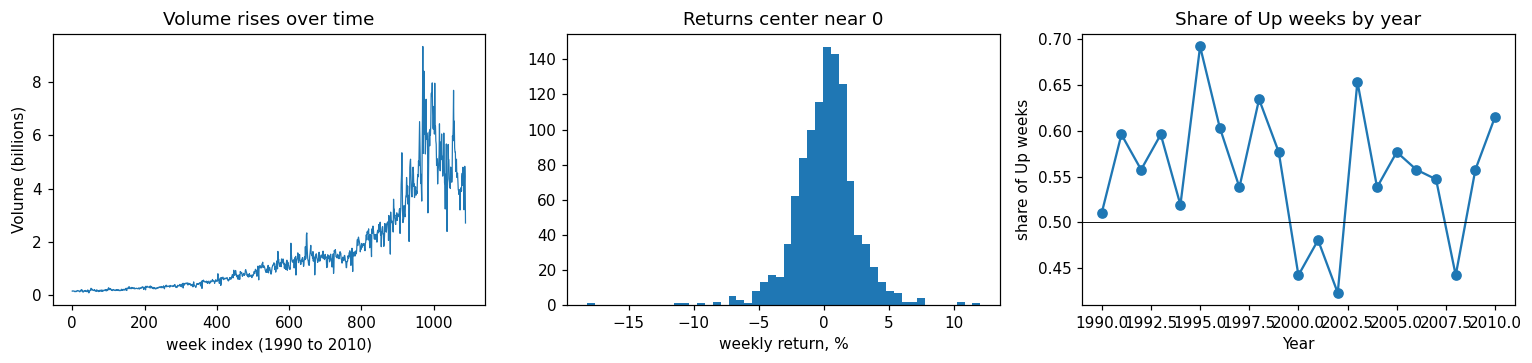

         Coef.  Std.Err.       z   P>|z|  [0.025  0.975]
const   0.2669    0.0859  3.1056  0.0019  0.0984  0.4353
Lag1   -0.0413    0.0264 -1.5626  0.1181 -0.0930  0.0105
Lag2    0.0584    0.0269  2.1754  0.0296  0.0058  0.1111
Lag3   -0.0161    0.0267 -0.6024  0.5469 -0.0683  0.0362
Lag4   -0.0278    0.0265 -1.0501  0.2937 -0.0797  0.0241
Lag5   -0.0145    0.0264 -0.5485  0.5833 -0.0662  0.0372
Volume -0.0227    0.0369 -0.6163  0.5377 -0.0951  0.0496
Actual     Down   Up
Predicted           
Down         54   48
Up          430  557
overall fraction correct 0.561; Up weeks caught 0.921; Down weeks caught 0.112; always-Up baseline 0.556


In [4]:
## ---- 2a. Applied Q13: summaries, full-data logistic regression, confusion matrix ---
weekly = load_data("Weekly")
weekly["Up"] = (weekly["Direction"] == "Up").astype(int)
# (a) numerical and graphical summaries
print(weekly.describe().T.round(3))
print("\nCorrelations (Year, Lags, Volume, Today):")
print(weekly.drop(columns=["Direction", "Up"]).corr().round(2))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].plot(weekly.index, weekly["Volume"], lw=.8); ax[0].set_xlabel("week index (1990 to 2010)"); ax[0].set_ylabel("Volume (billions)"); ax[0].set_title("Volume rises over time")
ax[1].hist(weekly["Today"], bins=50); ax[1].set_xlabel("weekly return, %"); ax[1].set_title("Returns center near 0")
weekly.groupby("Year")["Up"].mean().plot(ax=ax[2], marker="o"); ax[2].axhline(.5, c="k", lw=.6); ax[2].set_ylabel("share of Up weeks"); ax[2].set_title("Share of Up weeks by year")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A5_fig_weekly.png"), dpi=150); plt.show()

# (b) logistic regression on all the data
Xw = sm.add_constant(weekly[["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]])
glm_all = sm.Logit(weekly["Up"], Xw).fit(disp=0)
print(glm_all.summary2().tables[1].round(4))

# (c) confusion matrix on the same data (training error)
pred_all = (glm_all.predict(Xw) > .5).astype(int)
cm_all = pd.crosstab(pd.Series(pred_all, name="Predicted").map({0: "Down", 1: "Up"}), weekly["Direction"].rename("Actual"))
print(cm_all)
acc_all = float((pred_all == weekly["Up"]).mean())
up_recall = float(cm_all.loc["Up", "Up"] / weekly["Up"].sum()); down_recall = float(cm_all.loc["Down", "Down"] / (1 - weekly["Up"]).sum())
print(f"overall fraction correct {acc_all:.3f}; Up weeks caught {up_recall:.3f}; Down weeks caught {down_recall:.3f}; "
      f"always-Up baseline {weekly['Up'].mean():.3f}")

In [5]:
## ---- 2b. Applied Q13: 1990-2008 training, 2009-2010 test; (j) experiments ------
# (d)-(h): train 1990-2008, test 2009-2010, Lag2 only
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
tr, te = weekly["Year"] <= 2008, weekly["Year"] > 2008
def heldout(model, cols):
    model.fit(weekly.loc[tr, cols], weekly.loc[tr, "Up"])
    p = model.predict(weekly.loc[te, cols])
    cm = pd.crosstab(pd.Series(p, name="Predicted").map({0: "Down", 1: "Up"}),
                     weekly.loc[te, "Direction"].rename("Actual").reset_index(drop=True))
    return float((p == weekly.loc[te, "Up"].values).mean()), cm, float(p.mean())
weekly_q = {}
for name, model in [("(d) logistic", LogisticRegression(C=1e10, max_iter=1000)), ("(e) LDA", LDA()), ("(f) QDA", QDA()),
                    ("(g) KNN, K = 1", KNeighborsClassifier(1)), ("(h) naive Bayes", GaussianNB())]:
    acc, cm, share_up = heldout(model, ["Lag2"])
    weekly_q[name] = {"acc": acc, "share_pred_up": share_up}
    print(f"\n{name}: held-out accuracy {acc:.3f} (predicts Up for {share_up:.0%} of test weeks)"); print(cm)
print(f"\nAlways-Up baseline on 2009-2010: {weekly.loc[te, 'Up'].mean():.3f}")

# (j) a few other predictor sets, a transformation, an interaction, and K values (scored on the same held-out years)
weekly["Lag2_sq"] = weekly["Lag2"] ** 2; weekly["Lag1xLag2"] = weekly["Lag1"] * weekly["Lag2"]
trials, trial_cm = {}, {}
for cols in (["Lag1", "Lag2"], ["Lag2", "Lag2_sq"], ["Lag1", "Lag2", "Lag1xLag2"], ["Lag2", "Volume"]):
    for name, model in [("logistic", LogisticRegression(C=1e10, max_iter=1000)), ("LDA", LDA()), ("QDA", QDA()), ("naive Bayes", GaussianNB())]:
        key = f"{name}: {' + '.join(cols)}"
        trials[key], trial_cm[key], _ = heldout(model, cols)
knn_k = {}
for k in (1, 3, 5, 10, 20, 50, 100):
    key = f"KNN K = {k}: Lag2"
    trials[key], trial_cm[key], _ = heldout(KNeighborsClassifier(k), ["Lag2"])
    knn_k[k] = trials[key]
tbl = pd.Series(trials).sort_values(ascending=False)
print("\n(j) held-out accuracy, best first:"); print(tbl.round(3).head(12))
print(f"\nConfusion matrix for the best combination ({tbl.index[0]}), held-out 2009-2010:"); print(trial_cm[tbl.index[0]])
RESULTS["weekly"] = {"acc_all": acc_all, "up_recall_all": up_recall, "down_recall_all": down_recall,
                     "lag2_p": float(glm_all.pvalues["Lag2"]), "pvalues": {k: float(v) for k, v in glm_all.pvalues.items()},
                     "heldout": weekly_q, "baseline_up_test": float(weekly.loc[te, "Up"].mean()),
                     "j_best": [tbl.index[0], float(tbl.iloc[0])], "knn_k": knn_k}


(d) logistic: held-out accuracy 0.625 (predicts Up for 87% of test weeks)
Actual     Down  Up
Predicted          
Down          9   5
Up           34  56

(e) LDA: held-out accuracy 0.625 (predicts Up for 87% of test weeks)
Actual     Down  Up
Predicted          
Down          9   5
Up           34  56

(f) QDA: held-out accuracy 0.587 (predicts Up for 100% of test weeks)
Actual     Down  Up
Predicted          
Up           43  61

(g) KNN, K = 1: held-out accuracy 0.490 (predicts Up for 48% of test weeks)
Actual     Down  Up
Predicted          
Down         22  32
Up           21  29

(h) naive Bayes: held-out accuracy 0.587 (predicts Up for 100% of test weeks)
Actual     Down  Up
Predicted          
Up           43  61

Always-Up baseline on 2009-2010: 0.587

(j) held-out accuracy, best first:
logistic: Lag2 + Lag2_sq             0.625
QDA: Lag2 + Lag2_sq                  0.625
LDA: Lag2 + Lag2_sq                  0.615
KNN K = 20: Lag2                     0.596
logistic: Lag1 + Lag

In [6]:
## ---- 2c. Plain-language reading of Part 2 --------------------------------------
# ---- Plain-language reading of Part 2 (generated from the numbers above) ----
sig = [k for k, v in glm_all.pvalues.items() if k != "const" and v < .05]
print(f"* (a) Volume climbs steadily with Year (r = {weekly[['Year', 'Volume']].corr().iloc[0, 1]:.2f}); the lags are almost uncorrelated with Today, as expected for returns.")
print(f"* (b) Significant at 5%: {', '.join(sig) or 'none'} (Lag2 p = {glm_all.pvalues['Lag2']:.3f}). The other lags and Volume are not.")
print(f"* (c) Training accuracy {acc_all:.3f} vs {weekly['Up'].mean():.3f} for always guessing Up. The model calls almost every week Up: it catches {up_recall:.0%} of Up weeks but only {down_recall:.0%} of Down weeks.")
best = max(weekly_q, key=lambda k: weekly_q[k]["acc"])
print(f"* (d)-(h) Held-out 2009-2010 accuracy: " + "; ".join(f"{k} {v['acc']:.3f}" for k, v in weekly_q.items()) + ".")
print(f"* (i) Best: {best}. Logistic regression and LDA tie because with one predictor both draw a single cut-off on Lag2. "
      f"QDA and naive Bayes predict Up for every week, so they only match the always-Up rate; KNN with K = 1 is about a coin flip.")
lag2_acc = weekly_q["(d) logistic"]["acc"]
cmp_ = "only ties" if abs(tbl.iloc[0] - lag2_acc) < 1e-9 else ("beats" if tbl.iloc[0] > lag2_acc else "falls short of")
print(f"* (j) Best tried: {tbl.index[0]} at {tbl.iloc[0]:.3f}, which {cmp_} logistic regression on Lag2 alone ({lag2_acc:.3f}). "
      "Because these settings were compared on the test years themselves, the best-looking result overstates true performance.")

* (a) Volume climbs steadily with Year (r = 0.84); the lags are almost uncorrelated with Today, as expected for returns.
* (b) Significant at 5%: Lag2 (Lag2 p = 0.030). The other lags and Volume are not.
* (c) Training accuracy 0.561 vs 0.556 for always guessing Up. The model calls almost every week Up: it catches 92% of Up weeks but only 11% of Down weeks.
* (d)-(h) Held-out 2009-2010 accuracy: (d) logistic 0.625; (e) LDA 0.625; (f) QDA 0.587; (g) KNN, K = 1 0.490; (h) naive Bayes 0.587.
* (i) Best: (d) logistic. Logistic regression and LDA tie because with one predictor both draw a single cut-off on Lag2. QDA and naive Bayes predict Up for every week, so they only match the always-Up rate; KNN with K = 1 is about a coin flip.
* (j) Best tried: logistic: Lag2 + Lag2_sq at 0.625, which only ties logistic regression on Lag2 alone (0.625). Because these settings were compared on the test years themselves, the best-looking result overstates true performance.


## Kaggle data: Multi-Class Prediction of Obesity Risk (Playground Series S4E2)
The data load and cleaning cell is identical in Assignments 5 and 6, so both notebooks use the same data and features.
Put the Kaggle download (the zip, or `train.csv`, `test.csv`, `sample_submission.csv`) in **Google Drive → My Drive → DDS8555 → obesity**. If the files are not there, an upload button appears.

**Cleaning and features (kept the same in A5 and A6):** the competition files have no blank cells, so no rows are dropped or imputed (the cell prints the counts to confirm). The eight text columns are one-hot encoded. A level that appears only in the test file (for example CALC = "Always") gets all-zero dummies instead of an error. One feature is added: body-mass index, BMI = Weight / Height². The weight classes in the original study were defined from BMI, so BMI is the single most informative predictor; Weight and Height stay in as well.

In [7]:
## ---- 3. Load, clean, and fingerprint the Kaggle data ---------------------------
# ---- Load and clean the Kaggle obesity data (same cell in A5 and A6) ----
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in NEED):
    print("Choose the Kaggle zip (or the three CSV files):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
        zipfile.ZipFile(z).extractall(DATA_DIR)
missing = [f for f in NEED if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files in {DATA_DIR}: {missing}"

train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
TARGET = "NObeyesdad"
CAT = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]
NUMERIC = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "BMI"]
CLASSES = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
           "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]          # ordered light -> heavy
print("train:", train_raw.shape, " test:", test_raw.shape)
print("columns:", list(train_raw.columns))
EXPECTED = set(["id", TARGET] + CAT + NUMERIC[:-1])
assert EXPECTED <= set(train_raw.columns), f"Unexpected columns: {sorted(train_raw.columns)}"
assert len(test_raw) == len(sample), "test.csv and sample_submission.csv have different row counts"
assert train_raw["id"].is_unique and test_raw["id"].is_unique, "duplicate ids"
assert set(train_raw[TARGET]) <= set(CLASSES), f"unexpected classes: {set(train_raw[TARGET]) - set(CLASSES)}"

def add_features(df):
    out = df.copy()
    out["BMI"] = out["Weight"] / out["Height"] ** 2
    return out
train = add_features(train_raw); test = add_features(test_raw)
y = pd.Categorical(train[TARGET], categories=CLASSES)
y_codes = pd.Series(y.codes, index=train.index)          # 0..6 in CLASSES order

unseen = {c: sorted(set(test[c]) - set(train[c])) for c in CAT if set(test[c]) - set(train[c])}
print(f"missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
print(f"duplicate rows (excluding id): {int(train_raw.drop(columns='id').duplicated().sum())}")
print("levels in test but not in train (encoded as all-zero dummies):", unseen or "none")
counts = pd.Series(y).value_counts().reindex(CLASSES)
print("\nClass counts (training set):"); print(pd.DataFrame({"n": counts, "share": (counts / counts.sum()).round(3)}))
print("\nNumeric summary:"); print(train[NUMERIC].describe().T.round(3))

# ---- Provenance: fingerprint the exact input files (compare across re-runs) ----
import hashlib, datetime, platform
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
FINGERPRINT = {f: sha256(os.path.join(DATA_DIR, f)) for f in NEED}
print("\nRun started (UTC):", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"))
for f, hsh in FINGERPRINT.items():
    print(f"SHA-256 {f:<22} {hsh}")

# ---- Shared preprocessing and scoring helpers ----
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X = train[CAT + NUMERIC]; X_test = test[CAT + NUMERIC]

def prep(scale=True, drop="if_binary"):
    """One-hot the text columns (unseen test levels -> zeros); optionally standardize the numeric ones."""
    ohe = OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False)
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([("cat", ohe, CAT), ("num", num, NUMERIC)], verbose_feature_names_out=False)

def cv_eval(model, name, XX=None):
    """5-fold stratified CV predictions on the training set -> accuracy, confusion matrix, seconds."""
    t = time.time()
    p = cross_val_predict(model, X if XX is None else XX, y_codes, cv=SKF, n_jobs=-1)
    acc = accuracy_score(y_codes, p)
    print(f"{name:<34} CV accuracy {acc:.4f}   ({time.time() - t:.0f} s)")
    return {"cv_acc": float(acc), "cv_pred": p, "seconds": round(time.time() - t, 1)}

def write_submission(model, name, refit=True):
    """Fit on the full training set (unless already fitted), predict the test set, save in Kaggle's format."""
    if refit:
        model.fit(X, y_codes)
    pred = np.asarray(CLASSES)[model.predict(X_test).astype(int)]
    sub = pd.DataFrame({sample.columns[0]: test["id"].values, sample.columns[1]: pred})
    path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False)
    print("saved", path, sub.shape, "| predicted class shares:", sub.iloc[:, 1].value_counts(normalize=True).round(3).to_dict())
    if IN_COLAB:
        files.download(path)
    return model

def per_class_recall(pred):
    cm = confusion_matrix(y_codes, pred, labels=range(len(CLASSES)))
    return {c: float(cm[i, i] / cm[i].sum()) for i, c in enumerate(CLASSES)}

def plot_confusion(pred, title, path):
    cm = confusion_matrix(y_codes, pred, labels=range(len(CLASSES)), normalize="true")
    short = ["Insuff", "Normal", "Over I", "Over II", "Obese I", "Obese II", "Obese III"]
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > .5 else "black")
    ax.set_xticks(range(7)); ax.set_xticklabels(short, rotation=45, ha="right"); ax.set_yticks(range(7)); ax.set_yticklabels(short)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

RESULTS["data"] = {"n_train": int(len(train)), "n_test": int(len(test)), "missing_train": int(train_raw.isna().sum().sum()),
                   "missing_test": int(test_raw.isna().sum().sum()), "unseen_levels": unseen,
                   "class_counts": {k: int(v) for k, v in counts.items()},
                   "majority_share": float(counts.max() / counts.sum()), "sha256": FINGERPRINT}

train: (20758, 18)  test: (13840, 17)
columns: ['id', 'Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']
missing values: train 0, test 0
duplicate rows (excluding id): 0
levels in test but not in train (encoded as all-zero dummies): {'CALC': ['Always']}

Class counts (training set):
                        n  share
Insufficient_Weight  2523  0.122
Normal_Weight        3082  0.148
Overweight_Level_I   2427  0.117
Overweight_Level_II  2522  0.121
Obesity_Type_I       2910  0.140
Obesity_Type_II      3248  0.156
Obesity_Type_III     4046  0.195

Numeric summary:
          count    mean     std     min     25%     50%      75%      max
Age     20758.0  23.842   5.688  14.000  20.000  22.815   26.000   61.000
Height  20758.0   1.700   0.087   1.450   1.632   1.700    1.763    1.976
Weight  20758.0  87.888  26.379  39.000  66.000  84.065  111.601  165.057
FCVC    20758.0  

## Part 3. Four classifiers for the seven weight classes
All four models see the same features: eight one-hot text columns and nine standardized numeric columns (including BMI). Each is scored by 5-fold stratified CV accuracy on the training set, then refit on all training rows to predict the test set for Kaggle.

* **Model 1: multinomial logistic regression with a penalty (regularized regression).** A softmax model gives each class its own linear score. The ridge (L2) penalty strength *C* is chosen by CV over a grid; a lasso (L1) fit at the same *C* shows which inputs can be dropped.
* **Model 2: discriminant analysis.** LDA assumes each class is multivariate normal with one shared covariance matrix, which gives linear boundaries. QDA lets each class have its own covariance, which gives curved boundaries. Both are regularized: LDA uses Ledoit-Wolf shrinkage, and QDA's *reg_param* is chosen by CV. Both are submitted.
* **Model 3: Gaussian naive Bayes.** Treats every input as normal and independent of the others within a class. Its smoothing term is chosen by CV.
* **Model 4: support vector machine (RBF kernel).** One-vs-one SVMs with a radial kernel. *C* (the penalty on margin violations, which is its regularization knob) and *γ* are tuned on a stratified subsample to keep run time reasonable, then the chosen setting is scored by CV on all rows.

  ridge logistic C = 0.001   CV accuracy 0.7061
  ridge logistic C = 0.01    CV accuracy 0.7998
  ridge logistic C = 0.1     CV accuracy 0.8529
  ridge logistic C = 1       CV accuracy 0.8653
  ridge logistic C = 10      CV accuracy 0.8669
  ridge logistic C = 100     CV accuracy 0.8670
  ridge logistic C = 1000    CV accuracy 0.8669
  best C = 100; chosen C = 1 (strongest penalty within 0.5% of the best)
Model 1: ridge logistic (C = 1)    CV accuracy 0.8653   (6 s)
         lasso logistic (C = 1)    CV accuracy 0.8670   (29 s)
Model 2a: LDA (Ledoit-Wolf shrinkage) CV accuracy 0.8357   (1 s)
          LDA (no shrinkage)       CV accuracy 0.8279   (1 s)
  QDA reg_param = 0.0   CV accuracy 0.7274
  QDA reg_param = 0.01  CV accuracy 0.7693
  QDA reg_param = 0.05  CV accuracy 0.8016
  QDA reg_param = 0.1   CV accuracy 0.8086
  QDA reg_param = 0.3   CV accuracy 0.7854
  QDA reg_param = 0.6   CV accuracy 0.7562
Model 2b: QDA (reg_param = 0.1)    CV accuracy 0.8086   (1 s)
Model 3: Gaussian N

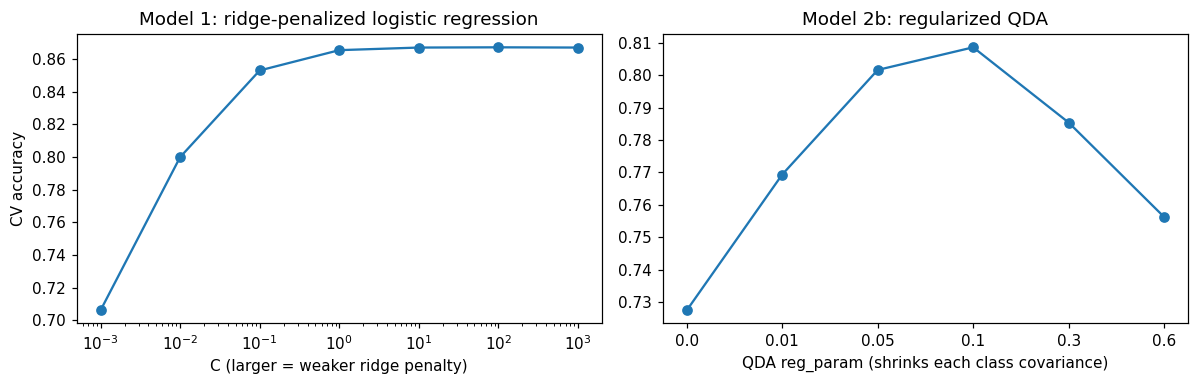

In [8]:
## ---- 4. Fit and tune the four classifiers (CV accuracy) ------------------------
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, GridSearchCV
# ---- Model 1: ridge-penalized multinomial logistic regression; C chosen by CV ----
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
logit_cv = {}
for C in C_GRID:
    m = make_pipeline(prep(), LogisticRegression(C=C, max_iter=4000))
    logit_cv[C] = float(cross_val_score(m, X, y_codes, cv=SKF, n_jobs=-1).mean())
    print(f"  ridge logistic C = {C:<7} CV accuracy {logit_cv[C]:.4f}")
# Parsimony rule (same idea as A4): the strongest penalty (smallest C) whose CV accuracy is within 0.5% of the best
C_top = max(logit_cv, key=logit_cv.get)
C_best = min(C for C, v in logit_cv.items() if v >= logit_cv[C_top] * 0.995)
print(f"  best C = {C_top}; chosen C = {C_best} (strongest penalty within 0.5% of the best)")
m1 = make_pipeline(prep(), LogisticRegression(C=C_best, max_iter=4000))
r1 = cv_eval(m1, f"Model 1: ridge logistic (C = {C_best})")
m1_lasso = make_pipeline(prep(), LogisticRegression(C=C_best, penalty="l1", solver="saga", max_iter=3000, tol=1e-3))
r1_lasso = cv_eval(m1_lasso, f"         lasso logistic (C = {C_best})")

# ---- Model 2: LDA (shrinkage) and QDA (reg_param by CV) ----
r2a = cv_eval(make_pipeline(prep(), LDA(solver="lsqr", shrinkage="auto")), "Model 2a: LDA (Ledoit-Wolf shrinkage)")
r2a_plain = cv_eval(make_pipeline(prep(), LDA()), "          LDA (no shrinkage)")
QDA_GRID = [0.0, 0.01, 0.05, 0.1, 0.3, 0.6]
qda_cv = {}
for a in QDA_GRID:
    try:
        qda_cv[a] = float(cross_val_score(make_pipeline(prep(), QDA(reg_param=a)), X, y_codes, cv=SKF, n_jobs=-1).mean())
        print(f"  QDA reg_param = {a:<5} CV accuracy {qda_cv[a]:.4f}")
    except ValueError as e:      # unregularized QDA can fail outright: a class covariance matrix is singular
        qda_cv[a] = float("nan")
        print(f"  QDA reg_param = {a:<5} FAILS: a class covariance matrix is not full rank (needs regularization)")
ok_q = {a: v for a, v in qda_cv.items() if v == v}            # skip failed (NaN) settings
a_best = max(a for a, v in ok_q.items() if v >= max(ok_q.values()) * 0.995)   # most regularization within 0.5% of the best
r2b = cv_eval(make_pipeline(prep(), QDA(reg_param=a_best)), f"Model 2b: QDA (reg_param = {a_best})")

# ---- Model 3: Gaussian naive Bayes; smoothing by CV ----
NB_GRID = [1e-9, 1e-6, 1e-3, 1e-2, 1e-1]
nb_cv = {v: float(cross_val_score(make_pipeline(prep(), GaussianNB(var_smoothing=v)), X, y_codes, cv=SKF, n_jobs=-1).mean()) for v in NB_GRID}
v_best = max(nb_cv, key=nb_cv.get)
r3 = cv_eval(make_pipeline(prep(), GaussianNB(var_smoothing=v_best)), f"Model 3: Gaussian NB (smoothing = {v_best:g})")

# ---- Model 4: RBF SVM; C and gamma tuned on a stratified subsample, then CV on all rows ----
n_sub = min(6000, len(X))
X_sub = X.groupby(y_codes, group_keys=False).apply(lambda g: g.sample(frac=n_sub / len(X), random_state=42))
gs = GridSearchCV(make_pipeline(prep(), SVC(kernel="rbf")), {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]},
                  cv=StratifiedKFold(3, shuffle=True, random_state=42), n_jobs=-1).fit(X_sub, y_codes.loc[X_sub.index])
svm_grid = {f"C={p['svc__C']}, gamma={p['svc__gamma']}": float(s) for p, s in zip(gs.cv_results_["params"], gs.cv_results_["mean_test_score"])}
print("  SVM tuning (subsample of", n_sub, "rows):", {k: round(v, 4) for k, v in svm_grid.items()})
svm_C, svm_g = gs.best_params_["svc__C"], gs.best_params_["svc__gamma"]
r4 = cv_eval(make_pipeline(prep(), SVC(kernel="rbf", C=svm_C, gamma=svm_g)), f"Model 4: SVM, RBF (C = {svm_C}, gamma = {svm_g})")

# Regularization plots: the penalty matters (rubric: applies regularized regression)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogx(list(logit_cv), list(logit_cv.values()), "o-"); ax[0].set_xlabel("C (larger = weaker ridge penalty)"); ax[0].set_ylabel("CV accuracy"); ax[0].set_title("Model 1: ridge-penalized logistic regression")
ax[1].plot([str(a) for a in qda_cv], [v if v == v else np.nan for v in qda_cv.values()], "o-"); ax[1].set_xlabel("QDA reg_param (shrinks each class covariance)"); ax[1].set_title("Model 2b: regularized QDA")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A5_fig_regularization.png"), dpi=150); plt.show()

### Assumption checks
* **Logistic regression** needs independent rows and no extreme collinearity among the inputs. Collinearity does not hurt prediction, but it makes single coefficients unstable. Height, Weight, and BMI are tied together by definition, so their VIFs (variance inflation factors) are checked below. The penalty is what keeps their coefficients stable.
* **LDA and QDA** assume the inputs are multivariate normal within each class. LDA also assumes every class has the same covariance matrix. The checks are per-class skewness, a Shapiro-Wilk test on a sample, and Box's M test for equal covariance matrices. With about 20,000 rows, any formal test will reject, so the size of the departure matters more than the *p*-value. The one-hot inputs are 0/1, so they cannot be normal; this is a known limit of using LDA and QDA with categorical inputs.
* **Naive Bayes** assumes the inputs are independent within each class. The within-class correlations below show how far that is from true.
* **SVM** makes no distributional assumption, but it needs inputs on a common scale (handled by standardizing).

In [9]:
## ---- 5. Assumption checks ------------------------------------------------------
from statsmodels.stats.outliers_influence import variance_inflation_factor
NUMV = [c for c in NUMERIC]
Z = (train[NUMV] - train[NUMV].mean()) / train[NUMV].std()
vif = {c: float(variance_inflation_factor(sm.add_constant(Z).values, i + 1)) for i, c in enumerate(NUMV)}
print("VIF:", {k: round(v, 1) for k, v in vif.items()})

skew = train.groupby(y.astype(str))[NUMV].skew().reindex(CLASSES)
print("\nWithin-class skewness (|skew| > 1 is a strong departure from normal):"); print(skew.round(2))
rng = np.random.default_rng(42)
shapiro = {}
for c in CLASSES:
    sub = train.loc[y == c, "BMI"]
    shapiro[c] = float(stats.shapiro(sub.sample(min(500, len(sub)), random_state=42)).pvalue)
print("\nShapiro-Wilk p-value for BMI within each class (500-row samples):", {k: f"{v:.1e}" for k, v in shapiro.items()})

def box_m(df, groups):
    """Box's M test for equal covariance matrices (chi-square approximation)."""
    k, p = len(groups.unique()), df.shape[1]; n = len(df)
    S = [df[groups == g].cov().values for g in groups.unique()]; ni = [int((groups == g).sum()) for g in groups.unique()]
    Sp = sum((m - 1) * s for m, s in zip(ni, S)) / (n - k)
    M = (n - k) * np.linalg.slogdet(Sp)[1] - sum((m - 1) * np.linalg.slogdet(s)[1] for m, s in zip(ni, S))
    c = (sum(1 / (m - 1) for m in ni) - 1 / (n - k)) * (2 * p * p + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    df_ = p * (p + 1) * (k - 1) / 2
    return float(M * (1 - c)), float(df_), float(stats.chi2.sf(M * (1 - c), df_))
bm = box_m(train[["Age", "Height", "Weight", "FAF", "TUE", "CH2O"]], pd.Series(y.astype(str), index=train.index))
print(f"\nBox's M (6 continuous inputs): chi2 = {bm[0]:,.0f}, df = {bm[1]:.0f}, p = {bm[2]:.1e} (0 means below 1e-300)")
sd_by_class = train.groupby(y.astype(str))[["Weight", "Age"]].std().reindex(CLASSES).round(2)
print("Within-class standard deviations (unequal spread is what QDA allows and LDA does not):"); print(sd_by_class)
corr_hw = {c: float(train.loc[y == c, ["Height", "Weight"]].corr().iloc[0, 1]) for c in CLASSES}
print("\nWithin-class correlation of Height and Weight (naive Bayes assumes 0):", {k: round(v, 2) for k, v in corr_hw.items()})
RESULTS["assumptions"] = {"vif": vif, "skew_max_abs": float(skew.abs().max().max()), "shapiro_bmi": shapiro,
                          "box_m": {"chi2": bm[0], "df": bm[1], "p": bm[2]}, "corr_hw": corr_hw,
                          "corr_hw_mean": float(np.mean(list(corr_hw.values())))}

VIF: {'Age': 1.3, 'Height': 15.0, 'Weight': 128.4, 'FCVC': 1.2, 'NCP': 1.1, 'CH2O': 1.2, 'FAF': 1.2, 'TUE': 1.1, 'BMI': 109.3}

Within-class skewness (|skew| > 1 is a strong departure from normal):
                      Age  Height  Weight  FCVC    NCP  CH2O   FAF   TUE   BMI
Insufficient_Weight  2.78   -0.13    0.90 -0.82  -1.14  0.07 -0.05  0.23  2.82
Normal_Weight        2.24    0.35    0.14 -0.06  -1.79 -0.04  0.40  0.45 -0.02
Overweight_Level_I   2.14    0.06   -0.10  0.30  -0.77 -0.09  0.56  0.84 -0.23
Overweight_Level_II  1.36   -0.39   -0.23  0.65  -1.24  0.02  0.59  0.38  0.76
Obesity_Type_I       1.27   -0.01    0.31  0.58  -0.96 -0.25  0.78  0.42  0.16
Obesity_Type_II      0.89   -0.33   -1.16 -0.64  -2.58 -0.32 -0.14  1.13 -0.48
Obesity_Type_III    -0.90    0.70    0.80  0.00 -63.35 -1.04  0.79 -0.14 -0.24

Shapiro-Wilk p-value for BMI within each class (500-row samples): {'Insufficient_Weight': '4.2e-25', 'Normal_Weight': '1.5e-03', 'Overweight_Level_I': '2.0e-17', 'Overwe

                                  CV accuracy  seconds
4: SVM (RBF)                           0.8821     30.4
1b: Multinomial logistic (lasso)       0.8670     28.5
1: Multinomial logistic (ridge)        0.8653      6.0
2a: LDA (shrinkage)                    0.8357      0.7
2b: QDA (regularized)                  0.8086      0.6
3: Gaussian naive Bayes                0.7697      0.8
majority-class rate: 0.1949


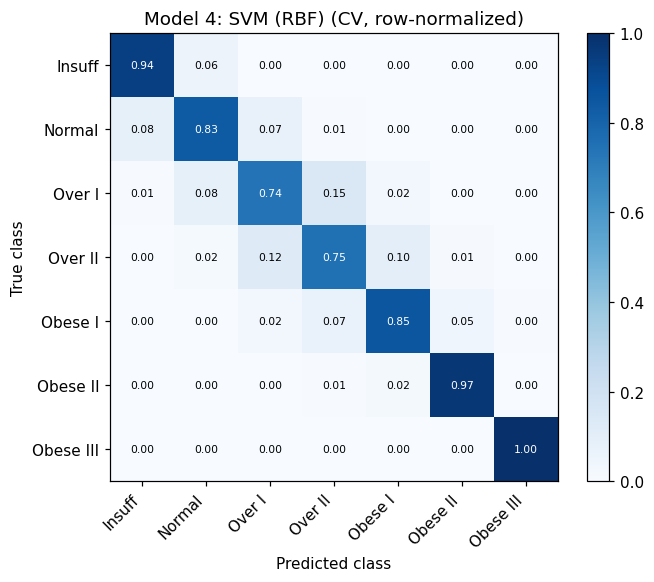

                     precision    recall  f1-score   support

Insufficient_Weight      0.895     0.940     0.917      2523
      Normal_Weight      0.871     0.834     0.852      3082
 Overweight_Level_I      0.745     0.739     0.742      2427
Overweight_Level_II      0.757     0.753     0.755      2522
     Obesity_Type_I      0.863     0.855     0.859      2910
    Obesity_Type_II      0.952     0.971     0.961      3248
   Obesity_Type_III      0.997     0.997     0.997      4046

           accuracy                          0.882     20758
          macro avg      0.869     0.870     0.869     20758
       weighted avg      0.881     0.882     0.882     20758

saved /content/drive/MyDrive/DDS8555/output/A5_model1_logistic.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.19, 'Obesity_Type_II': 0.158, 'Obesity_Type_I': 0.148, 'Normal_Weight': 0.143, 'Insufficient_Weight': 0.131, 'Overweight_Level_II': 0.126, 'Overweight_Level_I': 0.104}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A5_model2a_lda.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.19, 'Obesity_Type_II': 0.161, 'Obesity_Type_I': 0.139, 'Overweight_Level_II': 0.138, 'Insufficient_Weight': 0.137, 'Normal_Weight': 0.131, 'Overweight_Level_I': 0.104}


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A5_model4_svm.csv (13840, 2) | predicted class shares: {'Obesity_Type_III': 0.19, 'Obesity_Type_II': 0.156, 'Obesity_Type_I': 0.148, 'Normal_Weight': 0.145, 'Insufficient_Weight': 0.129, 'Overweight_Level_II': 0.126, 'Overweight_Level_I': 0.107}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Model 1 coefficients (standardized inputs; each class column is relative to the average class):
                                    Insufficient_Weight  Normal_Weight  Overweight_Level_I  Overweight_Level_II  \
BMI                                              -11.63          -6.62               -0.33                -0.79   
Weight                                           -10.96          -5.56               -3.98                 2.34   
Height                                             0.81           0.08                0.44                -0.86   
Age                                               -0.86          -0.42               -0.23                 0.16   
Gender_Male                                        1.41           1.28                0.34                 0.74   
family_history_with_overweight_yes                -1.07          -0.88               -0.87                 0.21   
FAVC_yes                                          -0.04          -0.04                0.34        

In [10]:
## ---- 6. Compare, interpret, and write the Kaggle files -------------------------
# ---- Compare, interpret, and write the Kaggle files ----
models = {"1: Multinomial logistic (ridge)": r1, "1b: Multinomial logistic (lasso)": r1_lasso, "2a: LDA (shrinkage)": r2a,
          "2b: QDA (regularized)": r2b, "3: Gaussian naive Bayes": r3, "4: SVM (RBF)": r4}
table = pd.DataFrame({k: {"CV accuracy": v["cv_acc"], "seconds": v["seconds"]} for k, v in models.items()}).T.sort_values("CV accuracy", ascending=False)
print(table.round(4)); print(f"majority-class rate: {RESULTS['data']['majority_share']:.4f}")
best_name = table.index[0]
plot_confusion(models[best_name]["cv_pred"], f"Model {best_name} (CV, row-normalized)", os.path.join(OUT_DIR, "A5_fig_confusion.png"))
print(classification_report(y_codes, models[best_name]["cv_pred"], target_names=CLASSES, digits=3))

m1 = write_submission(make_pipeline(prep(), LogisticRegression(C=C_best, max_iter=4000)), "A5_model1_logistic.csv")
write_submission(make_pipeline(prep(), LDA(solver="lsqr", shrinkage="auto")), "A5_model2a_lda.csv")
write_submission(make_pipeline(prep(), QDA(reg_param=a_best)), "A5_model2b_qda.csv")
write_submission(make_pipeline(prep(), GaussianNB(var_smoothing=v_best)), "A5_model3_naive_bayes.csv")
write_submission(make_pipeline(prep(), SVC(kernel="rbf", C=svm_C, gamma=svm_g)), "A5_model4_svm.csv")

# Interpreting Model 1: coefficients on the standardized scale (one column per class)
names = m1[0].get_feature_names_out()
coef = pd.DataFrame(m1[-1].coef_.T, index=names, columns=CLASSES)
show = [c for c in ["BMI", "Weight", "Height", "Age", "Gender_Male", "family_history_with_overweight_yes", "FAVC_yes", "FAF", "CH2O"] if c in coef.index]
print("\nModel 1 coefficients (standardized inputs; each class column is relative to the average class):"); print(coef.loc[show].round(2))
lasso_fit = make_pipeline(prep(), LogisticRegression(C=C_best, penalty="l1", solver="saga", max_iter=3000, tol=1e-3)).fit(X, y_codes)
zero_all = [n for n, row in zip(names, lasso_fit[-1].coef_.T) if np.all(np.abs(row) < 1e-8)]
print("inputs the lasso drops for every class:", zero_all or "none")

RESULTS_FILE = "A5_results.json"
RESULTS["models"] = {k: {"cv_acc": v["cv_acc"], "seconds": v["seconds"], "recall": per_class_recall(v["cv_pred"])} for k, v in models.items()}
RESULTS["tuning"] = {"logit_C": logit_cv, "C_best": C_best, "qda_reg": qda_cv, "qda_best": a_best, "nb_smoothing": nb_cv,
                     "nb_best": v_best, "svm_grid": svm_grid, "svm_C": svm_C, "svm_gamma": str(svm_g), "svm_subsample": n_sub,
                     "lda_plain_acc": r2a_plain["cv_acc"]}
RESULTS["best"] = best_name
bp_ = models[best_name]["cv_pred"]; wrong = bp_ != y_codes.values
RESULTS["adjacent_error_share"] = float((np.abs(bp_ - y_codes.values)[wrong] == 1).mean())
RESULTS["logit_coef"] = coef.loc[show].round(4).to_dict()
RESULTS["lasso_dropped"] = zero_all

In [11]:
## ---- 7. Plain-language reading of Part 3 ---------------------------------------
# ---- Plain-language reading of Part 3 (generated from the numbers above) ----
acc = table["CV accuracy"]
beat = "All four model types beat" if acc.min() > RESULTS['data']['majority_share'] else "Not every model beats"
print(f"* {beat} the majority-class rate ({RESULTS['data']['majority_share']:.3f}). Best: {best_name} ({acc.iloc[0]:.4f}); worst: {table.index[-1]} ({acc.iloc[-1]:.4f}).")
print(f"* The ridge penalty matters: CV accuracy runs from {min(logit_cv.values()):.4f} at C = {min(logit_cv, key=logit_cv.get)} (heavy penalty) "
      f"to {max(logit_cv.values()):.4f} at C = {C_top}. The chosen C = {C_best} is the strongest penalty within 0.5% of the best ({logit_cv[C_best]:.4f}).")
q0 = "fails outright (a class covariance matrix is singular)" if qda_cv[0.0] != qda_cv[0.0] else f"scores {qda_cv[0.0]:.4f}"
print(f"* QDA needs regularization here: chosen reg_param = {a_best} (the most shrinkage within 0.5% of the best); unregularized QDA {q0}. "
      "Several one-hot columns are constant or nearly constant within a class, which makes those covariance matrices singular.")
nb_rank = list(table.index).index("3: Gaussian naive Bayes") + 1
print(f"* Naive Bayes ranks {nb_rank} of {len(table)}. Its independence assumption is badly wrong here: Height and Weight correlate at about "
      f"{RESULTS['assumptions']['corr_hw_mean']:.2f} within classes, and BMI is built from both, so it counts the same evidence more than once.")
rc = RESULTS["models"][best_name]["recall"]
print(f"* Per-class recall for the best model: " + ", ".join(f"{k} {v:.2f}" for k, v in rc.items()) + ". "
      f"{RESULTS['adjacent_error_share']:.0%} of its errors put a person in a neighbouring class (for example Overweight I vs II), where BMI ranges overlap.")
fmt_p = lambda p: "p < .001" if p < .001 else f"p = {p:.3f}"
print(f"* Assumptions: Box's M rejects equal covariances ({fmt_p(RESULTS['assumptions']['box_m']['p'])}), the largest within-class |skew| is {RESULTS['assumptions']['skew_max_abs']:.1f}, "
      f"and Height, Weight, BMI have VIFs of {vif['Height']:.0f}, {vif['Weight']:.0f}, {vif['BMI']:.0f}. The normal-theory models (LDA, QDA, naive Bayes) all rest on assumptions the data break; the SVM needs none of them.")

* All four model types beat the majority-class rate (0.195). Best: 4: SVM (RBF) (0.8821); worst: 3: Gaussian naive Bayes (0.7697).
* The ridge penalty matters: CV accuracy runs from 0.7061 at C = 0.001 (heavy penalty) to 0.8670 at C = 100. The chosen C = 1 is the strongest penalty within 0.5% of the best (0.8653).
* QDA needs regularization here: chosen reg_param = 0.1 (the most shrinkage within 0.5% of the best); unregularized QDA scores 0.7274. Several one-hot columns are constant or nearly constant within a class, which makes those covariance matrices singular.
* Naive Bayes ranks 6 of 6. Its independence assumption is badly wrong here: Height and Weight correlate at about 0.75 within classes, and BMI is built from both, so it counts the same evidence more than once.
* Per-class recall for the best model: Insufficient_Weight 0.94, Normal_Weight 0.83, Overweight_Level_I 0.74, Overweight_Level_II 0.75, Obesity_Type_I 0.85, Obesity_Type_II 0.97, Obesity_Type_III 1.00. 88% of its errors

In [12]:
## ---- 8. Environment report and results JSON ------------------------------------
# ---- Environment report (the Python equivalent of R's sessionInfo()) ----
import importlib, platform
VERSIONS = {"python": platform.python_version()}
for pkg in ("numpy", "pandas", "sklearn", "statsmodels", "scipy", "matplotlib", "ISLP"):
    try:
        VERSIONS[pkg] = importlib.import_module(pkg).__version__
    except Exception:
        VERSIONS[pkg] = "not installed"
print("Environment:", VERSIONS)
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")
RESULTS["environment"] = VERSIONS

# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items() if not str(k).startswith("_")}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, np.ndarray):
        return None
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

Environment: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'ISLP': '0.5.1'}
Total run time: 3.4 min
RESULTS_JSON_START
{"weekly": {"acc_all": 0.5610651974288338, "up_recall_all": 0.9206611570247933, "down_recall_all": 0.1115702479338843, "lag2_p": 0.02960136900327745, "pvalues": {"const": 0.0018988482466837646, "Lag1": 0.11814437549081942, "Lag2": 0.02960136900327745, "Lag3": 0.5469239075928736, "Lag4": 0.29365335514080326, "Lag5": 0.5833482550610372, "Volume": 0.5376747700928137}, "heldout": {"(d) logistic": {"acc": 0.625, "share_pred_up": 0.8653846153846154}, "(e) LDA": {"acc": 0.625, "share_pred_up": 0.8653846153846154}, "(f) QDA": {"acc": 0.5865384615384616, "share_pred_up": 1.0}, "(g) KNN, K = 1": {"acc": 0.49038461538461536, "share_pred_up": 0.4807692307692308}, "(h) naive Bayes": {"acc": 0.5865384615384616, "share_pred_up": 1.0}}, "baseline_up_test": 0.5865384615384616, "j_best":